# Green synthesis: predicting nanoparticle size and shape from the recipe

**Question.** Given a *green-synthesis recipe* (a metal salt reduced by a plant, fungal or bacterial extract), can we predict the **size** and **shape** of the nanoparticles, for a paper the model has never seen?

Green synthesis is harder to model than chemical synthesis. The "reducing agent" is a biological extract whose chemistry is rarely characterised, and it varies with species, plant part, season and extraction solvent. The initial analysis already found negative R² for size here; this notebook asks *why* and what *can* be learned.

The workflow and evaluation protocol mirror the chemical-synthesis notebook (see its introduction for the full list of changes against the initial version): **paper-grouped repeated CV, no imputation of targets, imputation inside the folds, log-size target, baselines, paired bootstrap over papers, permutation importance on held-out papers.**

**Contents:** 1 load → 2 audit → 3 clean → 4 feature engineering → 5 EDA and variance decomposition → 6 protocol → 7 size models → 8 ablation & importance → 9 shape models → 10 conclusions.

In [1]:
import sys, re
from pathlib import Path
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import np_utils as U

U.set_style()
pd.set_option("display.max_columns", 50, "display.width", 160, "display.max_colwidth", 60)
DATA = Path("../data/Nanoparticles_Synthesis_Dataset - Green_Synthesis.xlsx")
SEED = 42
N_REPEATS = 5

## 1. Load and repair text

In [2]:
raw = pd.read_excel(DATA)
raw.columns = [U.fix_text(c) for c in raw.columns]
for c in raw.columns:
    if not pd.api.types.is_numeric_dtype(raw[c]):
        raw[c] = raw[c].map(U.fix_text)
print(f"{raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head(3)

141 rows x 21 columns


,NanoParticles,Coating,Reactant,Conc of Reactant(mmol/L),Extract(Reducing Agent),Conc. of Extract,Reactant:Extract(v/v),Method,Temperature(°C),Agitation,Time(min),Average Size(nm),Min Size(nm),Max Size(nm),Shape,Dispersity,Conc of NPs,Surface area,yield,Reference,Title of Article
0,AgNPs,NaN,AgNO3,NaN,Opuntia ficus-indica,NaN,NaN,NaN,80.0,NaN,135.0,30,NaN,NaN,Spherical,NaN,53.2,NaN,54.8,1,Comparative antibacterial potential of silver nanopartic...
1,AgNPs,NaN,AgNO3,NaN,Bacillus megaterium,NaN,NaN,NaN,80.0,NaN,135.0,35,NaN,NaN,Spherical,NaN,20.4,NaN,21.0,1,Comparative antibacterial potential of silver nanopartic...
2,AgNPs,NaN,AgNO3,NaN,Aspergillus niger,NaN,NaN,NaN,80.0,NaN,135.0,42,NaN,NaN,Spherical,NaN,67.2,NaN,69.2,1,Comparative antibacterial potential of silver nanopartic...


## 2. Data audit

In [3]:
audit = pd.DataFrame({
    "missing_%": (raw.isna().mean() * 100).round(1),
    "n_unique": raw.nunique(),
    "example": raw.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
}).sort_values("missing_%", ascending=False)
display(audit)

df = raw.copy()
df["paper"] = df["Title of Article"]
df["paper"] = df["paper"].fillna("ref_" + df["Reference"].astype("string"))
df["paper"] = [p if isinstance(p, str) and "<NA>" not in p and p != "ref_nan" else f"row_{i}"
               for i, p in zip(df.index, df["paper"])]
per_paper = df.groupby("paper").size()
print(f"\n{df['paper'].nunique()} papers; rows per paper: median {per_paper.median():.0f}, max {per_paper.max()}")

,missing_%,n_unique,example
Surface area,100.0,0,None
Agitation,99.3,1,130rpm
Max Size(nm),97.2,4,20.0
Min Size(nm),97.2,3,10.0
Method,95.0,7,XRD
yield,94.3,8,54.8
Conc of NPs,93.6,7,53.2
Conc. of Extract,85.8,8,15.0
Coating,83.7,21,TSC
Dispersity,74.5,5,Polydisperse



83 papers; rows per paper: median 1, max 27


**Decision: columns with more than ~70% missing values are not used** (coating, extract concentration, method, agitation, min/max size, dispersity, NP concentration, surface area, yield). With 8 of 141 rows reporting yield and 1 reporting agitation there is nothing to learn from.

## 3. Cleaning

**Targets.** Size is parsed to a number (a range such as `5-30` becomes its midpoint). Shape becomes `spherical` vs `non-spherical`. **Rows with a missing target are dropped, not imputed.**

In [4]:
df["size_nm"] = df["Average Size(nm)"].map(U.parse_number)
df.loc[~(df["size_nm"] > 0), "size_nm"] = np.nan
df["log_size"] = np.log10(df["size_nm"])

def shape_group(s):
    if not isinstance(s, str) or not s.strip():
        return np.nan
    return "spherical" if "spher" in s.lower() else "non-spherical"
df["shape_group"] = df["Shape"].map(shape_group)

print("size available :", df["size_nm"].notna().sum(), "of", len(df))
print("shape available:", df["shape_group"].notna().sum(), "of", len(df))
display(pd.crosstab(df["Shape"].str.strip().str.lower().fillna("(missing)"), df["shape_group"].fillna("(missing)")))

size available : 127 of 141
shape available: 130 of 141


shape_group,(missing),non-spherical,spherical
Shape,,,
(missing),11,0,0
conical,0,1,0
cubical,0,3,0
irregular,0,1,0
quasi-spherical,0,0,3
rectangular,0,1,0
rock stone,0,1,0
rod-shaped,0,1,0
spherical,0,0,118


**Numeric columns.** `Reactant:Extract(v/v)` is stored as text and sometimes as a clock time (Excel turned the ratio `2:1` into `02:01:00`); `parse_number` handles both. Reactant concentration is already in mmol/L.

In [5]:
df["reactant_mM"]   = df["Conc of Reactant(mmol/L)"].map(U.parse_number)
df["ratio_RE"]      = df["Reactant:Extract(v/v)"].map(U.parse_number)       # reactant volume : extract volume
df["temperature_C"] = df["Temperature(°C)"].map(U.parse_number)
df["time_min"]      = df["Time(min)"].map(U.parse_number)
print(df[["reactant_mM", "ratio_RE", "temperature_C", "time_min"]].describe().round(2))

       reactant_mM  ratio_RE  temperature_C  time_min
count       116.00     98.00         129.00    118.00
mean         25.74      7.50          44.43    751.42
std          97.61     14.11          43.29   1216.73
min           0.01      0.01          23.00      5.00
25%           1.00      0.67          25.00     75.00
50%           1.00      3.25          25.00    120.00
75%          10.00      9.00          60.00   1440.00
max        1000.00    100.00         450.00   5760.00


## 4. Feature engineering

* **Nanoparticle family** from the free-text name (`AgNPs`, `Ag-NPs`...).
* **Extract kind**: plant, microbe (bacteria/fungi), algae, other. A bacterial culture supernatant and a leaf extract are different chemistry.
* **Extract genus**: the first word of the extract name, as a weak proxy for phytochemistry; rare genera are pooled by the encoder.
* **Extract volume fraction** `1 / (1 + ratio)`: how much of the mixture is extract. More extract usually means more reducing and capping biomolecules.
* log-transforms for concentration, ratio and time (they span orders of magnitude).

In [6]:
def np_family(name):
    n = str(name).lower()
    if "gold and" in n:                                          return "other"      # mixed Au/Ag entry
    if n.startswith("ag") or "silver" in n:                      return "Ag"
    if n.startswith("au") or "gold" in n:                        return "Au"
    if n.startswith("cu") or "copper" in n:                      return "Cu"
    if n.startswith("zn"):                                       return "Zn"
    if n.startswith("se"):                                       return "Se"
    if n.startswith("fe") or "iron" in n:                        return "Fe oxide"
    if n.startswith(("pd", "pt")) or "platinum" in n:            return "Pt/Pd"
    return "other"

MICROBE = ["bacillus", "streptomyces", "aspergillus", "pseudomonas", "thermus", "halomonas", "nocardiopsis",
           "fung", "bacteri", "biologically", "endophytic", "actinomycet"]
ALGAE   = ["ulva", "botryococcus", "algae", "seaweed"]
def extract_kind(s):
    if not isinstance(s, str) or not s.strip():
        return np.nan
    n = s.lower()
    if any(k in n for k in MICROBE): return "microbe"
    if any(k in n for k in ALGAE):   return "algae"
    if "pomacea" in n:               return "other"
    return "plant"

def extract_genus(s):
    if not isinstance(s, str):
        return np.nan
    m = re.match(r"[a-z]+", s.strip().lower())
    return m.group(0) if m else np.nan

df["np_family"]     = df["NanoParticles"].map(np_family)
df["extract_kind"]  = df["Extract(Reducing Agent)"].map(extract_kind)
df["extract_genus"] = df["Extract(Reducing Agent)"].map(extract_genus)

log10 = lambda s: np.log10(s.where(s > 0))
df["log_reactant_mM"]   = log10(df["reactant_mM"])
df["log_ratio_RE"]      = log10(df["ratio_RE"])
df["extract_fraction"]  = 1 / (1 + df["ratio_RE"])
df["log_time_min"]      = log10(df["time_min"])

NUM = ["log_reactant_mM", "log_ratio_RE", "extract_fraction", "temperature_C", "log_time_min"]
CAT = ["np_family", "extract_kind", "extract_genus"]
FEATURES = NUM + CAT
display(df[["np_family", "extract_kind"]].apply(lambda s: s.value_counts(dropna=False).to_dict()).to_frame("counts"))
print("most common extract genera:", df["extract_genus"].value_counts().head(8).to_dict())

,counts
np_family,"{'Ag': 101, 'Cu': 9, 'Se': 8, 'Zn': 6, 'Fe oxide': 5, 'o..."
extract_kind,"{'plant': 113, 'microbe': 16, nan: 8, 'algae': 3, 'other..."


most common extract genera: {'wedelia': 27, 'magnolia': 6, 'pomelo': 6, 'streptomyces': 4, 'halomonas': 3, 'achillea': 3, 'allium': 2, 'thymus': 2}


**Rows without an extract or without a reactant are dropped** (a recipe without a reducing agent is not a recipe). Everything else stays; missing numeric values are handled inside the CV folds.

In [7]:
df = df.dropna(subset=["Reactant", "Extract(Reducing Agent)"]).reset_index(drop=True)
size_df  = df.dropna(subset=["log_size"]).reset_index(drop=True)
shape_df = df.dropna(subset=["shape_group"]).reset_index(drop=True)
shape_df["is_nonspherical"] = (shape_df["shape_group"] == "non-spherical").astype(int)

print(f"SIZE : {len(size_df)} rows from {size_df['paper'].nunique()} papers")
print(f"SHAPE: {len(shape_df)} rows from {shape_df['paper'].nunique()} papers, "
      f"{shape_df['is_nonspherical'].sum()} non-spherical ({shape_df['is_nonspherical'].mean():.0%}) "
      f"from {shape_df.loc[shape_df['is_nonspherical'] == 1, 'paper'].nunique()} papers")
display((size_df[NUM].isna().mean() * 100).round(1).to_frame("missing %").T)

SIZE : 120 rows from 69 papers
SHAPE: 121 rows from 70 papers, 9 non-spherical (7%) from 7 papers


,log_reactant_mM,log_ratio_RE,extract_fraction,temperature_C,log_time_min
missing %,12.5,23.3,23.3,6.7,15.0


## 5. Exploratory analysis and variance decomposition

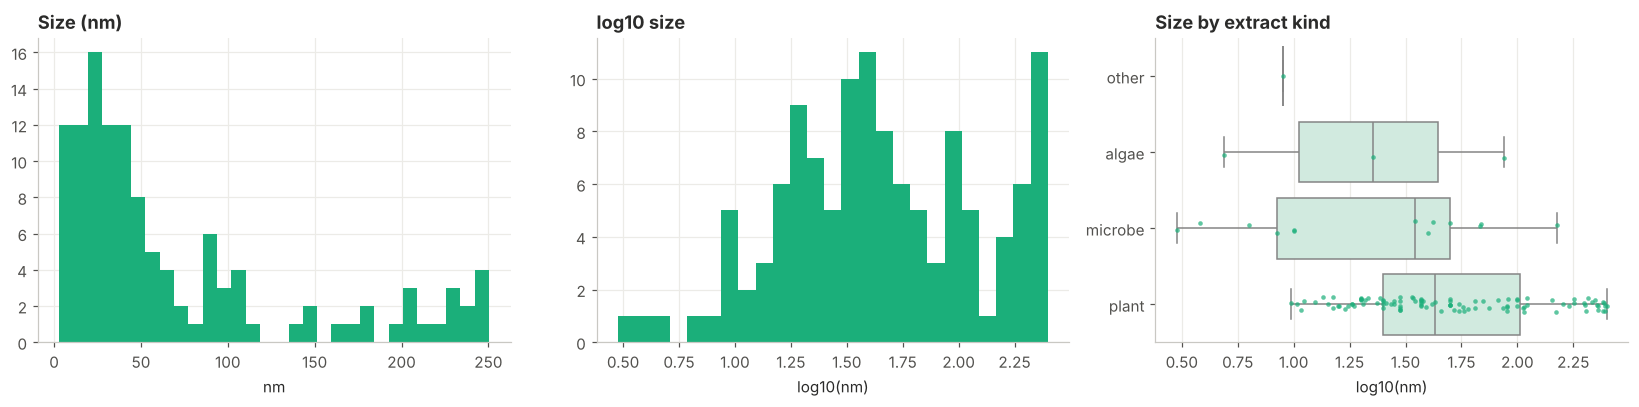

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(size_df["size_nm"], bins=30, color=U.AQUA); ax[0].set_title("Size (nm)"); ax[0].set_xlabel("nm")
ax[1].hist(size_df["log_size"], bins=25, color=U.AQUA); ax[1].set_title("log10 size"); ax[1].set_xlabel("log10(nm)")
order = size_df.groupby("extract_kind")["log_size"].median().sort_values().index
sns.boxplot(data=size_df, y="extract_kind", x="log_size", order=order, color="#cdeee0", fliersize=0, ax=ax[2], linewidth=1)
sns.stripplot(data=size_df, y="extract_kind", x="log_size", order=order, color=U.AQUA, size=3, alpha=.7, ax=ax[2])
ax[2].set_title("Size by extract kind"); ax[2].set_xlabel("log10(nm)"); ax[2].set_ylabel("")
plt.tight_layout(); plt.show()

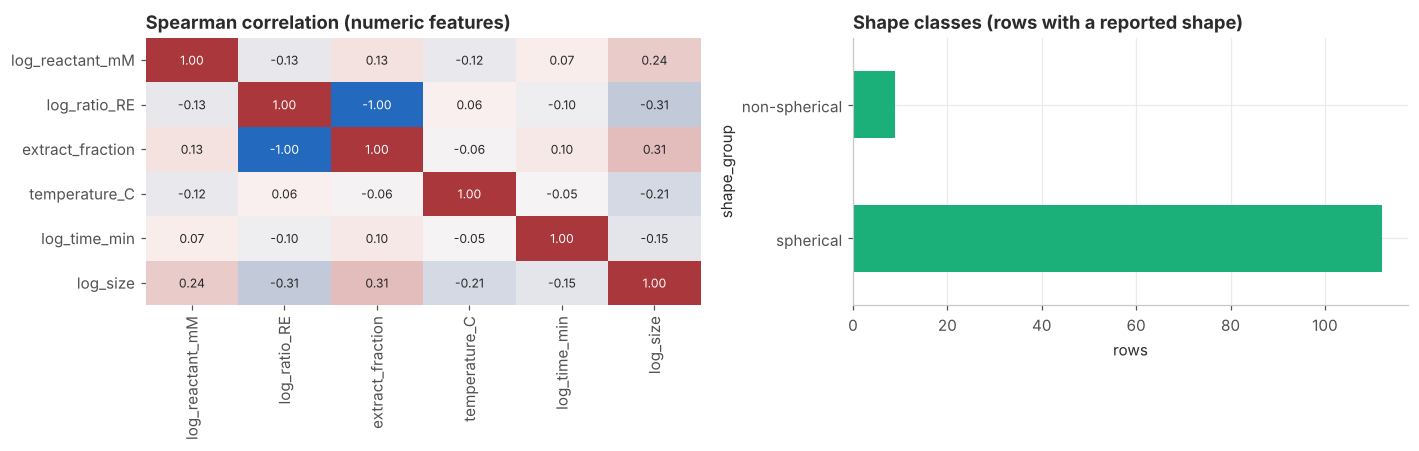

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
corr = size_df[NUM + ["log_size"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, cbar=False, ax=ax[0], annot_kws={"size": 8})
ax[0].set_title("Spearman correlation (numeric features)")
shape_df["shape_group"].value_counts().plot.barh(color=U.AQUA, ax=ax[1])
ax[1].set_title("Shape classes (rows with a reported shape)"); ax[1].set_xlabel("rows")
plt.tight_layout(); plt.show()

### 5b. Between-paper vs within-paper variation

* **ICC**: share of log-size variance explained purely by which paper a row comes from.
* **Within-paper effects**: each paper's own mean is subtracted from both feature and target, then correlated. This isolates what changes *when the same lab turns one knob*.

ICC (share of log-size variance explained by paper identity): 0.79
papers with 2+ size rows: 11 of 69


,within_paper_rho,ci_low,ci_high,n_papers,n_rows
feature,,,,,
log_reactant_mM,NaN,NaN,NaN,1,27
log_ratio_RE,NaN,NaN,NaN,3,33
extract_fraction,NaN,NaN,NaN,3,33
temperature_C,0.02,-0.46,0.69,5,20
log_time_min,NaN,NaN,NaN,2,8


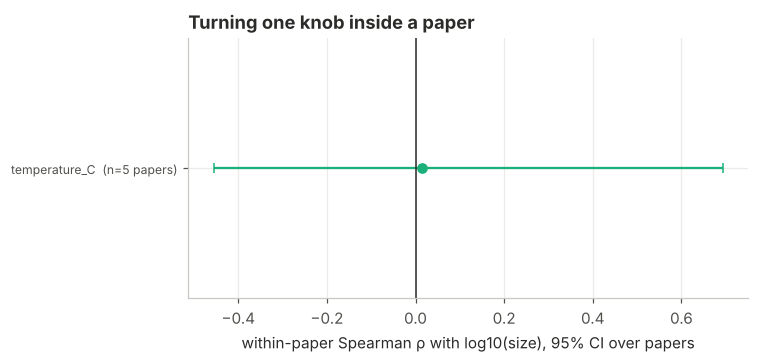

In [10]:
icc = U.icc_between_papers(size_df["log_size"], size_df["paper"])
print(f"ICC (share of log-size variance explained by paper identity): {icc:.2f}")
print(f"papers with 2+ size rows: {(size_df.groupby('paper').size() > 1).sum()} of {size_df['paper'].nunique()}")

eff = U.within_paper_effects(size_df, NUM, "log_size", "paper", n_boot=1000, seed=SEED)
display(eff.round(2))

fig, ax = plt.subplots(figsize=(7, 3.4))
e = eff.dropna().iloc[::-1]
if len(e):
    ax.errorbar(e["within_paper_rho"], range(len(e)), xerr=[e["within_paper_rho"] - e["ci_low"], e["ci_high"] - e["within_paper_rho"]],
                fmt="o", color=U.AQUA, capsize=3)
    ax.set_yticks(range(len(e))); ax.set_yticklabels([f"{i}  (n={int(r.n_papers)} papers)" for i, r in e.iterrows()], fontsize=8)
ax.axvline(0, color=U.INK, lw=1)
ax.set_xlabel("within-paper Spearman ρ with log10(size), 95% CI over papers")
ax.set_title("Turning one knob inside a paper"); plt.tight_layout(); plt.show()

## 6. Evaluation protocol

Same as the chemical notebook: repeated 5-fold CV **grouped by paper**; imputation, scaling, encoding and tuning inside each training fold (nested, grouped); global and per-family baselines; fold error `10^MAE`; paired bootstrap over papers.

## 7. Size prediction

In [11]:
Xs, ys, gs = size_df[FEATURES], size_df["log_size"].to_numpy(), size_df["paper"].to_numpy()
zoo = U.regression_zoo(NUM, CAT, seed=SEED)

oof_size, score_size = {}, {}
for name, est in zoo.items():
    oof_size[name], score_size[name] = U.repeated_group_cv(est, Xs, ys, gs, "reg", n_repeats=N_REPEATS, seed=SEED)
    print(f"{name:32s} done")

tbl = pd.concat({k: v.mean() for k, v in score_size.items()}, axis=1).T
tbl["MAE_log10 sd"] = [v["MAE_log10"].std() for v in score_size.values()]
display(tbl[["fold_error", "MAE_log10", "MAE_log10 sd", "R2_log", "within_2x", "median_abs_err_nm"]].round(3))

Baseline: global median          done
Baseline: median per NP family   done


Ridge                            done


Random forest                    done


Gradient boosting                done


,fold_error,MAE_log10,MAE_log10 sd,R2_log,within_2x,median_abs_err_nm
Baseline: global median,2.500,0.398,0.010,-0.214,0.463,27.205
Baseline: median per NP family,2.662,0.425,0.004,-0.395,0.438,28.300
Ridge,2.617,0.418,0.016,-0.308,0.423,27.161
Random forest,2.498,0.397,0.012,-0.242,0.468,21.642
Gradient boosting,2.784,0.443,0.037,-0.531,0.410,26.977


,model,vs,ΔMAE_log10,95% CI low,95% CI high,significant
0,Ridge,global median,0.020,-0.010,0.047,no
1,Ridge,median per NP family,-0.008,-0.042,0.025,no
2,Random forest,global median,-0.000,-0.038,0.030,no
3,Random forest,median per NP family,-0.028,-0.068,0.005,no
4,Gradient boosting,global median,0.046,-0.003,0.086,no
5,Gradient boosting,median per NP family,0.018,-0.030,0.060,no


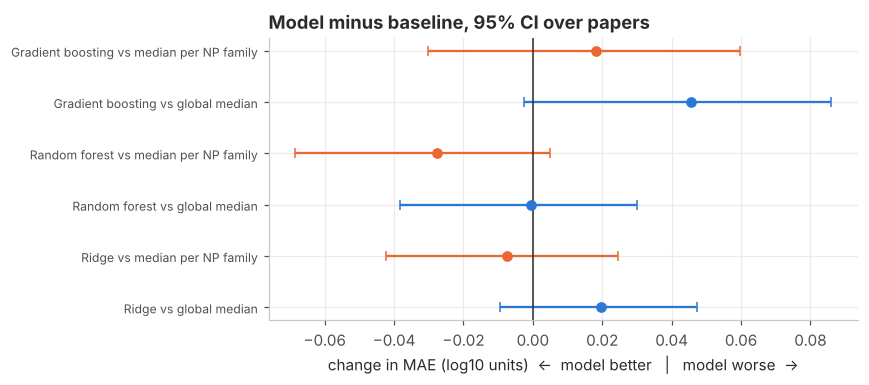

In [12]:
loss = {k: U.per_row_loss(ys, v, "reg") for k, v in oof_size.items()}
rows = []
for m in ["Ridge", "Random forest", "Gradient boosting"]:
    for b in ["Baseline: global median", "Baseline: median per NP family"]:
        d, (lo, hi) = U.paired_group_bootstrap(loss[m], loss[b], gs, seed=SEED)
        rows.append({"model": m, "vs": b.replace("Baseline: ", ""), "ΔMAE_log10": d, "95% CI low": lo, "95% CI high": hi,
                     "significant": "yes" if hi < 0 else ("worse" if lo > 0 else "no")})
cmp_size = pd.DataFrame(rows); display(cmp_size.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, r in cmp_size.iterrows():
    col = U.BLUE if r["vs"].startswith("global") else U.ORANGE
    ax.errorbar(r["ΔMAE_log10"], i, xerr=[[r["ΔMAE_log10"] - r["95% CI low"]], [r["95% CI high"] - r["ΔMAE_log10"]]],
                fmt="o", color=col, capsize=3, ms=6)
ax.axvline(0, color=U.INK, lw=1)
ax.set_yticks(range(len(cmp_size))); ax.set_yticklabels([f"{m} vs {v}" for m, v in zip(cmp_size["model"], cmp_size["vs"])], fontsize=8)
ax.set_xlabel("change in MAE (log10 units)  ←  model better   |   model worse  →")
ax.set_title("Model minus baseline, 95% CI over papers")
plt.tight_layout(); plt.show()

best model on MAE: Random forest


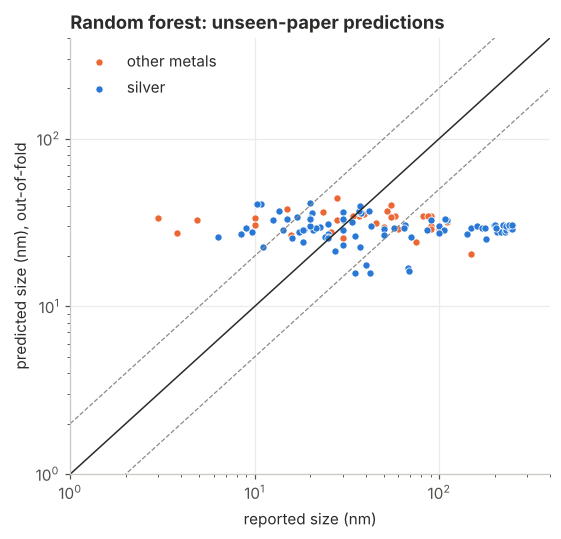

In [13]:
best = tbl.loc[[k for k in tbl.index if not k.startswith("Baseline")], "MAE_log10"].idxmin()
print("best model on MAE:", best)
pred = oof_size[best].mean(axis=0)
fig, ax = plt.subplots(figsize=(5.2, 5))
is_ag = (size_df["np_family"] == "Ag").to_numpy()
ax.scatter(10 ** ys[~is_ag], 10 ** pred[~is_ag], s=22, color=U.ORANGE, edgecolor="white", linewidth=.5, label="other metals")
ax.scatter(10 ** ys[is_ag],  10 ** pred[is_ag],  s=22, color=U.BLUE,   edgecolor="white", linewidth=.5, label="silver")
lim = [1, 400]; ax.plot(lim, lim, color=U.INK, lw=1); ax.plot(lim, [l * 2 for l in lim], "--", color=U.GREY, lw=.8); ax.plot(lim, [l / 2 for l in lim], "--", color=U.GREY, lw=.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("reported size (nm)"); ax.set_ylabel("predicted size (nm), out-of-fold")
ax.set_title(f"{best}: unseen-paper predictions"); ax.legend()
plt.tight_layout(); plt.show()

## 8. Which inputs matter? Ablation and permutation importance

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

def rf_reg(num, cat):
    return Pipeline([("pre", U.make_preprocessor(num, cat)),
                     ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.6, random_state=SEED, n_jobs=2))])

sets = {
    "1. family only":                         ([], ["np_family"]),
    "2. + extract kind and genus":            ([], ["np_family", "extract_kind", "extract_genus"]),
    "3. + numeric recipe (conc., ratio, T, time)": (NUM, CAT),
}
rows = []
for name, (num, cat) in sets.items():
    _, sc = U.repeated_group_cv(rf_reg(num, cat), Xs[num + cat], ys, gs, "reg", n_repeats=N_REPEATS, seed=SEED)
    rows.append({"features": name, "MAE_log10": sc["MAE_log10"].mean(), "sd": sc["MAE_log10"].std(), "fold_error": sc["fold_error"].mean()})
b = score_size["Baseline: median per NP family"]["MAE_log10"]
rows.append({"features": "(reference) median per family", "MAE_log10": b.mean(), "sd": b.std(), "fold_error": 10 ** b.mean()})
ablation = pd.DataFrame(rows).set_index("features"); display(ablation.round(3))

,MAE_log10,sd,fold_error
features,,,
1. family only,0.436,0.011,2.729
2. + extract kind and genus,0.398,0.004,2.502
"3. + numeric recipe (conc., ratio, T, time)",0.415,0.015,2.604
(reference) median per family,0.425,0.004,2.662


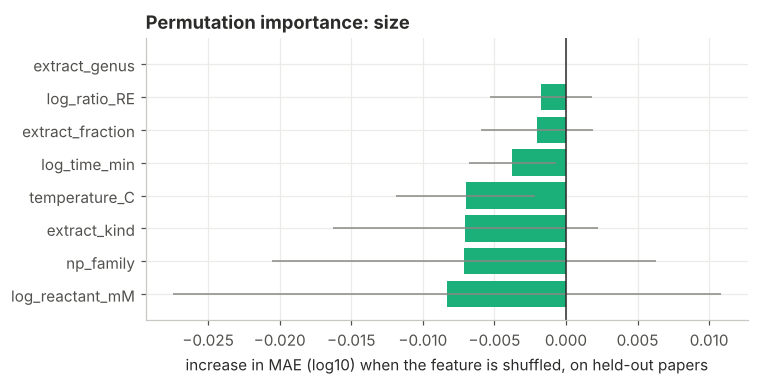

,importance,sd_over_folds
extract_genus,0.0000,0.0000
log_ratio_RE,-0.0017,0.0036
extract_fraction,-0.0020,0.0039
log_time_min,-0.0038,0.0031
temperature_C,-0.0070,0.0049
extract_kind,-0.0070,0.0093
np_family,-0.0071,0.0134
log_reactant_mM,-0.0083,0.0191


In [15]:
imp = U.grouped_permutation_importance(rf_reg(NUM, CAT), Xs, ys, gs, "reg", n_perm=15, seed=SEED)
fig, ax = plt.subplots(figsize=(7, 3.6))
ip = imp.iloc[::-1]
ax.barh(ip.index, ip["importance"], xerr=ip["sd_over_folds"], color=U.AQUA, error_kw=dict(ecolor=U.GREY, lw=1))
ax.axvline(0, color=U.INK, lw=1)
ax.set_xlabel("increase in MAE (log10) when the feature is shuffled, on held-out papers")
ax.set_title("Permutation importance: size"); plt.tight_layout(); plt.show()
display(imp.round(4))

## 9. Shape prediction (spherical vs non-spherical)

Only a handful of rows are non-spherical, and they come from very few papers, so this section is mostly a demonstration of *why not to report accuracy*: always answering "spherical" is already right about nine times in ten.

In [16]:
Xc, yc, gc = shape_df[FEATURES], shape_df["is_nonspherical"].to_numpy(), shape_df["paper"].to_numpy()
print(f"positive rate (non-spherical): {yc.mean():.2f}; always-'spherical' accuracy: {1 - yc.mean():.2f}")
zoo_c = U.classification_zoo(NUM, CAT, seed=SEED)

oof_shape, score_shape = {}, {}
for name, est in zoo_c.items():
    oof_shape[name], score_shape[name] = U.repeated_group_cv(est, Xc, yc, gc, "clf", n_repeats=N_REPEATS, seed=SEED)
    print(f"{name:32s} done")
tbl_c = pd.concat({k: v.mean() for k, v in score_shape.items()}, axis=1).T
tbl_c["ROC_AUC sd"] = [v["ROC_AUC"].std() for v in score_shape.values()]
display(tbl_c[["ROC_AUC", "ROC_AUC sd", "PR_AUC", "Brier", "balanced_acc@0.5"]].round(3))

positive rate (non-spherical): 0.07; always-'spherical' accuracy: 0.93


Baseline: class prior            done


Baseline: prior per NP family    done


Logistic regression              done


Random forest                    done


,ROC_AUC,ROC_AUC sd,PR_AUC,Brier,balanced_acc@0.5
Baseline: class prior,0.500,0.000,0.075,0.069,0.500
Baseline: prior per NP family,0.509,0.129,0.196,0.079,0.503
Logistic regression,0.443,0.034,0.174,0.253,0.377
Random forest,0.294,0.043,0.095,0.097,0.495


In [17]:
loss_c = {k: U.per_row_loss(yc, v, "clf") for k, v in oof_shape.items()}
rows = []
for m in ["Logistic regression", "Random forest"]:
    for b in ["Baseline: class prior", "Baseline: prior per NP family"]:
        d, (lo, hi) = U.paired_group_bootstrap(loss_c[m], loss_c[b], gc, seed=SEED)
        rows.append({"model": m, "vs": b.replace("Baseline: ", ""), "ΔBrier": d, "95% CI low": lo, "95% CI high": hi,
                     "significant": "yes" if hi < 0 else ("worse" if lo > 0 else "no")})
cmp_shape = pd.DataFrame(rows); display(cmp_shape.round(3))

,model,vs,ΔBrier,95% CI low,95% CI high,significant
0,Logistic regression,class prior,0.184,0.087,0.264,worse
1,Logistic regression,prior per NP family,0.173,0.073,0.256,worse
2,Random forest,class prior,0.028,0.017,0.037,worse
3,Random forest,prior per NP family,0.018,-0.004,0.032,no


## 10. Conclusions

**What the numbers say** (120 size rows from 69 papers; 121 shape rows from 70 papers; all scores are on papers the model never saw).

* **Size is not predictable from this data.** Random forest is typically off by a factor of **2.50**, identical to predicting the global median (**2.50**; difference 0.000 log10 units, 95% CI [−0.038, 0.030]). Ridge and gradient boosting are slightly worse (2.62 and 2.78). The negative R² of the initial analysis is not an artefact of a bad model; it is what the data allows.
* **Why: almost all variation is between papers.** The ICC is **0.79**: 79% of the variance in log-size is explained by which paper a row comes from (the extract, the lab, the way size was measured), and only 11 of 69 papers report more than one size. With one row per paper, the effect of a knob (concentration, ratio, time) cannot be separated from everything else that differs between papers. The within-paper analysis confirms this: for most features it cannot be estimated at all, and for temperature (5 papers) the interval spans −0.46 to 0.69.
* **Extract identity is the real driver, and it is the least describable.** The ablation shows extract kind and genus as the only features that lower the error (0.398, versus 0.436 for family alone), and that only matches the global median. Permutation importance is zero or negative for every feature. A "reducing agent" such as *Wedelia urticifolia* is a mixture of unknown composition, and a single paper (the *Wedelia* study) contributes 27 of the 120 rows.
* **Shape.** Only 9 of 121 rows are non-spherical, from 7 papers. A held-out-paper evaluation of that is not estimable: the ROC-AUCs (random forest 0.29, logistic regression 0.44) are below chance, which with so few positive papers is noise, not a finding. This is why accuracy alone (0.93 for "always spherical") is meaningless here.

**Compared with chemical synthesis.** The chemical dataset has stronger within-paper structure (ICC 0.57, concentrations varied inside papers) and shows at least a directional concentration effect. The green dataset mostly has single-condition papers, and its key variable (the extract) is hard to encode.

**What would change this**
1. Standardised characterisation of the extract (species and plant part, extraction solvent, phenolic or total-reducing capacity) as numeric covariates instead of a name.
2. Papers that vary one condition at a time (pH, temperature, extract-to-salt ratio); these are the rows that carry the knob effect. pH, a key variable in green synthesis, is not recorded in the current sheet at all.
3. Hierarchical models with paper-level random effects, and an explicit measurement-method covariate.
4. A larger dataset, built with automated extraction and human verification.

**Limitations of this notebook.** Extract genus is the first word of a free-text name and is only a weak proxy; microbial extracts are identified by keyword rules; hyper-parameter grids are small; and the shape analysis is included to illustrate the problem, not to answer it.